In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/sample_submission.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/train.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/test.csv


### Directory links
**Train data** - `/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/train.csv`

**Test data** - `/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/test.csv`


**Sample submission** - `/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/sample_submission.csv`

In [2]:
# Basic imports

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Basic information about data.

Here, we explore different data types present in the training dataset. We will also present descriptive statistics of numerical columns before pre-processing.

In [3]:
# importing files

df = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/train.csv')

df_test = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/test.csv')

In [4]:
df.head(2)  #output shows all feature columns along with the target variable.

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357


In [5]:
df_test.head(2) #output shows only feature columns. The target variable is missing as mentioned.

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left
0,0,Vistara,UK-816,Bangalore,Morning,zero,Afternoon,Delhi,Economy,2.67,18.0
1,1,Air_India,AI-440,Chennai,Early_Morning,zero,Morning,Delhi,Economy,NaN,5.0


In [6]:
print("--- Train Data Summary ---")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}") 

print("\n--- Test Data Summary ---")
print(f"Shape: {df_test.shape}")
print(f"Columns: {df_test.columns.tolist()}")

--- Train Data Summary ---
Shape: (40000, 12)
Columns: ['id', 'airline', 'flight', 'source', 'departure', 'stops', 'arrival', 'destination', 'class', 'duration', 'days_left', 'price']

--- Test Data Summary ---
Shape: (10000, 11)
Columns: ['id', 'airline', 'flight', 'source', 'departure', 'stops', 'arrival', 'destination', 'class', 'duration', 'days_left']


## 1.1 Identify data types of different columns

In [7]:
df.info() #train data information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           40000 non-null  int64  
 1   airline      35387 non-null  object 
 2   flight       40000 non-null  object 
 3   source       40000 non-null  object 
 4   departure    35208 non-null  object 
 5   stops        37681 non-null  object 
 6   arrival      40000 non-null  object 
 7   destination  40000 non-null  object 
 8   class        40000 non-null  object 
 9   duration     36987 non-null  float64
 10  days_left    35562 non-null  float64
 11  price        40000 non-null  int64  
dtypes: float64(2), int64(2), object(8)
memory usage: 3.7+ MB


#### 3 types of data are present, namely - int64, object, and float64.

| Dtype     |Columns                                                                |
|-----------|-----------------------------------------------------------------------|
| int64     |id, price                                                              |
| float64   |duration, days_left                                                    |
| object    |airline, flight, source, departure, stops, arrival, destination, class |

We can conclude that the majority of the columns present belong to the object data type.

In [8]:
df.describe(include='object')

,airline,flight,source,departure,stops,arrival,destination,class
count,35387,40000,40000,35208,37681,40000,40000,40000
unique,6,869,6,6,3,6,6,2
top,Vistara,0.00E+00,Delhi,Morning,one,Night,Mumbai,Economy
freq,15063,5240,8189,8302,31439,12348,7821,27536


## 1.2 Descriptive statistics of numerical columns

In [9]:
df.describe() #shows descriptive statistics including mean, median, mode, etc.

,id,duration,days_left,price
count,40000.00000,36987.000000,35562.000000,40000.00000
mean,19999.50000,12.004088,26.197936,20801.49025
std,11547.14972,7.108063,13.469232,22729.14842
min,0.00000,0.830000,1.000000,1105.00000
25%,9999.75000,6.670000,15.000000,4687.00000
50%,19999.50000,11.080000,26.000000,7353.00000
75%,29999.25000,15.920000,38.000000,42521.00000
max,39999.00000,47.080000,49.000000,114704.00000


# 2. Data Pre-processing


To ensure `Data Integrity`, `Improve Accuracy`, and `Enhance Efficiency`, we will drop duplicates first and then handle missing values and outliers.

However, for simplicity we will maintain the cell order in a similar manner given in out assignment website.

**``` Please run dropping duplicates cell first, followed by missing values cell, and finally outliers cell```**

**```Order of running cells: 2.2 > 2.1 > 2.3```**

## 2.1 Identifying and handling the missing values

In [10]:
df.isna().sum()

id                0
airline        4613
flight            0
source            0
departure      4792
stops          2319
arrival           0
destination       0
class             0
duration       3013
days_left      4438
price             0
dtype: int64

```
This shows there are missing values in the following columns:
- airline
- departure
- stops
- duration
- days_left
```

In [11]:
print("airline:", df.airline.unique())
print("departure:", df.departure.unique())
print("stops:", df.stops.unique())
print("duration:", df.duration.unique())
print("days_left:", df.days_left.unique())
print("flight:", df.flight.unique())
print("source:", df.source.unique())
print("arrival:", df.arrival.unique())
print("destination:", df.destination.unique())
print("class:", df['class'].unique())


# Upon inspection of the output of this tab, we found out that there are other unknown values like
#'0.00E+00' in the flight column of the data. This is created most likely due to a CSV auto-conversion 
# and it’s a data quality issue we should fix before encoding or modeling.

print("test data flight:", df_test.flight.unique())

airline: ['Vistara' 'Air_India' 'SpiceJet' nan 'AirAsia' 'Indigo' 'GO_FIRST']
departure: ['Early_Morning' 'Evening' nan 'Morning' 'Afternoon' 'Night' 'Late_Night']
stops: ['one' 'zero' 'two_or_more' nan]
duration: [  nan 16.08  2.92  1.5   4.83  6.17 15.67  4.42  4.67  7.08 24.25 12.75
 14.5  17.42  5.33  8.25 16.42 11.83 25.5   1.75  9.75 16.17 12.42 14.25
 10.83  4.75  8.17 19.25  9.08 12.33  2.08 10.67  7.75  6.33 16.   13.83
 19.17 12.5   5.92  2.    8.58 15.08 16.92 11.67 11.75 12.    2.83 24.33
 14.    7.67 11.25  8.75  9.92  8.33 17.33  8.83  8.08 10.42 33.67 19.33
  7.5   3.67  5.67 11.17 14.83  5.17 25.67 12.83 13.75 13.67 24.   13.92
 25.42  4.5   9.25 24.92  9.   17.5   2.17  1.33  8.42 12.08  3.92  7.58
  6.67 16.67 26.17  6.5   7.    6.    5.42  9.58 33.   15.    9.83 24.17
  9.67  6.25 11.92 25.75  1.25 15.25 12.25  7.42 20.25 29.17 11.42 24.58
  9.17  1.17 14.08 21.58  5.5  23.08 12.17  6.42 20.58 13.25 25.17 15.5
 15.92  5.25 12.92  6.83  7.25 17.25 11.58  1.83  2.5   7

In [12]:
# Handling the above exception in the flight column

df['flight'].replace(to_replace=r'^\d+\.\d+[eE][+-]?\d+$',value=np.nan,regex=True,inplace=True)
df_test['flight'].replace(to_replace=r'^\d+\.\d+[eE][+-]?\d+$',value=np.nan,regex=True,inplace=True)

/tmp/ipykernel_13/3129678305.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['flight'].replace(to_replace=r'^\d+\.\d+[eE][+-]?\d+$',value=np.nan,regex=True,inplace=True)
/tmp/ipykernel_13/3129678305.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 

In [13]:
df.isna().sum()

id                0
airline        4613
flight         5922
source            0
departure      4792
stops          2319
arrival           0
destination       0
class             0
duration       3013
days_left      4438
price             0
dtype: int64

`This now includes mishandled data in the flights column as well. Now we can go ahead with the imputation.`

In [14]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

#Separating feature and target column
X = df.drop(columns=['price'])
y = df['price']


#cols for imputation
cat_cols = ['airline', 'departure', 'stops', 'flight']  #to be imputed with mode
num_cols = ['duration', 'days_left']  #to be imputed with median

#defining imputers
c_imputer = SimpleImputer(strategy='most_frequent')
n_imputer = SimpleImputer(strategy='median')

ct = ColumnTransformer(transformers=[
    ('categorical_imp', c_imputer, cat_cols),
    ('numerical_imp', n_imputer, num_cols)],
                      remainder='passthrough')

#fitting
ct.fit(X)

#transforming datasets
X_imputed_nondf = ct.transform(X)
df_test_imputed_nondf = ct.transform(df_test)

# cols = X.columns.tolist()
remaining_cols = [col for col in X.columns if col not in cat_cols + num_cols]
final_columns = cat_cols + num_cols + remaining_cols

X_imputed =  pd.DataFrame(X_imputed_nondf, columns=final_columns)
df_test_imputed = pd.DataFrame(df_test_imputed_nondf, columns=final_columns)

In [15]:
df_test_imputed.head(2)

,airline,departure,stops,flight,duration,days_left,id,source,arrival,destination,class
0,Vistara,Morning,zero,UK-816,2.67,18.0,0,Bangalore,Afternoon,Delhi,Economy
1,Air_India,Early_Morning,zero,AI-440,11.08,5.0,1,Chennai,Morning,Delhi,Economy


In [16]:
X_imputed.head(2)

,airline,departure,stops,flight,duration,days_left,id,source,arrival,destination,class
0,Vistara,Early_Morning,one,UK-930,11.08,40.0,0,Mumbai,Night,Chennai,Business
1,Air_India,Evening,one,AI-539,16.08,26.0,1,Chennai,Morning,Mumbai,Economy


In [17]:
print("Missing values in test data set:", df_test_imputed.isna().sum())
print("Missing values in train data set:", X_imputed.isna().sum())

#finished handling missing values.

Missing values in test data set: airline        0
departure      0
stops          0
flight         0
duration       0
days_left      0
id             0
source         0
arrival        0
destination    0
class          0
dtype: int64
Missing values in train data set: airline        0
departure      0
stops          0
flight         0
duration       0
days_left      0
id             0
source         0
arrival        0
destination    0
class          0
dtype: int64


## 2.2 Identifying and handling duplicates

In [18]:
print("Duplicate rows in train data:", df.duplicated().sum())
print("Duplicate rows in test data:", df_test.duplicated().sum())

print("Since no duplicates were found no need to drop any row.")

# In case duplicates are found, run the following commands
df = df.drop_duplicates(inplace=True)
df_test = df_test.drop_duplicates(inplace=True)

Duplicate rows in train data: 0
Duplicate rows in test data: 0
Since no duplicates were found no need to drop any row.


## 2.3 Identifying and handling outliers

In this sub-section, we are going to handle the outliers present in numeric columns. There are 4 numeric columns present in the data set:
- id
- price
- duration
- days_left

We have decided to ignore the `id` column as it serves purely as an identifier and holds no analytical value for outlier detection. Similarly, the `price` column will not be treated for outliers; our model should be robust enough to handle the wide range of prices observed in real-world data, including potentially "outrageous" ones, as these represent genuine market values.

Our primary focus for outlier handling will be on the `duration` and `days_left` columns. Instead of dropping rows with outliers (which could lead to significant data loss), we will be clipping (or capping) these outliers. 

This involves setting an upper and lower bound (calculated using the Interquartile Range method) and replacing any values exceeding these bounds with the respective boundary value. This approach helps to reduce the influence of extreme values while preserving the overall dataset size and underlying data distribution

In [19]:
def remove_outliers(df,col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR 
    upper_bound = Q3 + 1.5 * IQR

    #outliers lie above upper_bound and below lower_bound
    outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    print(f"Outliers present in {col}: {outliers_count}")
        
    df[col] = np.clip(df[col], lower_bound, upper_bound)

    #outliers after capping
    outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    print(f"Outliers present in {col} after capping: {outliers_count}")

remove_outliers(X_imputed,'days_left')
remove_outliers(X_imputed,'duration')

remove_outliers(df_test_imputed,'days_left')
remove_outliers(df_test_imputed,'duration')

Outliers present in days_left: 0
Outliers present in days_left after capping: 0
Outliers present in duration: 470
Outliers present in duration after capping: 0
Outliers present in days_left: 0
Outliers present in days_left after capping: 0
Outliers present in duration: 81
Outliers present in duration after capping: 0


# 3. Exploratory Data Analysis(EDA)


## 3.1 Target variable distribution


/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


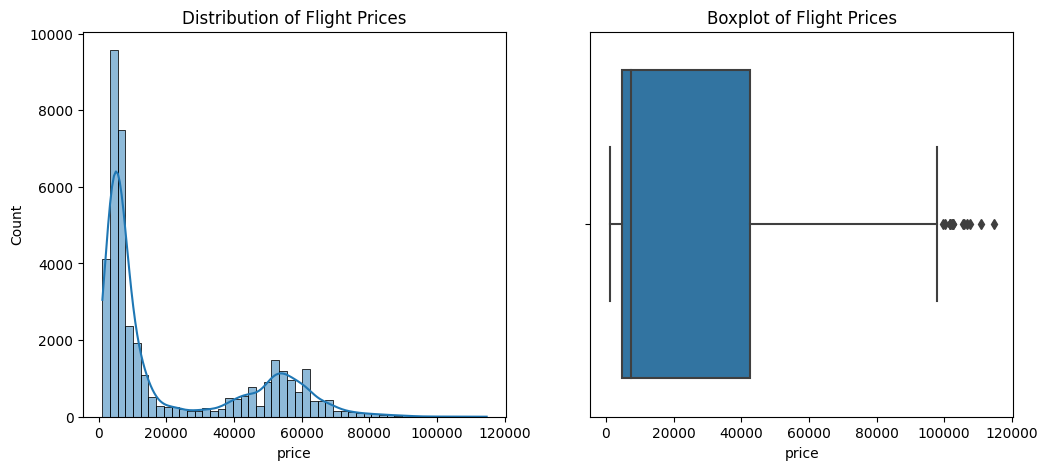

In [20]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(y, bins=50, kde=True)
plt.title("Distribution of Flight Prices")

plt.subplot(1, 2, 2)
sns.boxplot(x=y)
plt.title("Boxplot of Flight Prices")
plt.show()


### `Insight` - The distribution of flight prices is right-skewed, with a significant number of high-priced outliers, indicating possible business-class or last-minute bookings.

## 3.2 Price variation by different Class

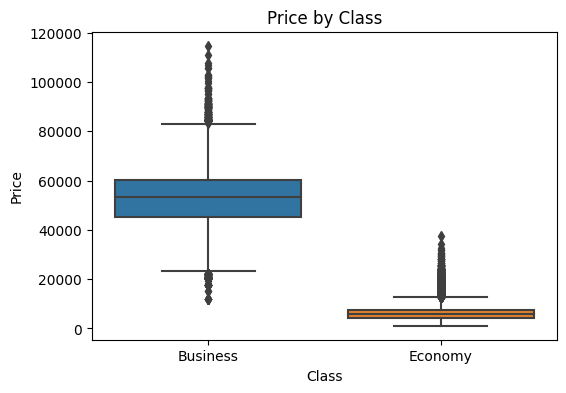

In [21]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=X_imputed['class'], y=y)
plt.title("Price by Class")
plt.xlabel("Class")
plt.ylabel("Price")
plt.show()


### `Insight` - Business class flights are significantly more expensive than economy, showing a clear price separation. The median price in business class is more than double, and there are more high-priced outliers, indicating either luxury services or last-minute bookings.

## 3.3 Price variation by different Airlines.

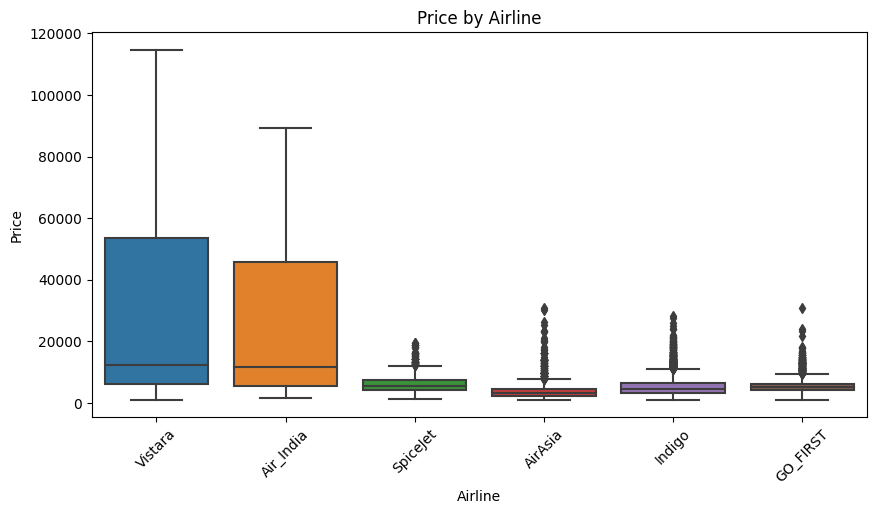

In [22]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=X_imputed['airline'], y=y)
plt.title("Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.show()


### `Insight` - Airlines like Vistara and Air India tend to have higher ticket prices, while IndiGo, SpiceJet, and Go First offer more budget-friendly options. This suggests airline choice is a strong predictor of pricing, likely tied to service tier and route popularity.

## 3.4 Correlation matrix

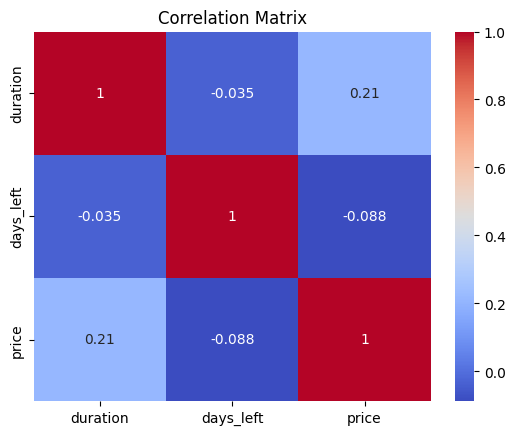

In [23]:
corr_df = X_imputed[['duration', 'days_left']].copy()
corr_df['price'] = y

sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()


### `Insight` - duration shows a moderate positive correlation with price, while days_left has a moderate negative correlation, supporting earlier scatterplot observations.

## 3.5 Box plot for days_left and duration column

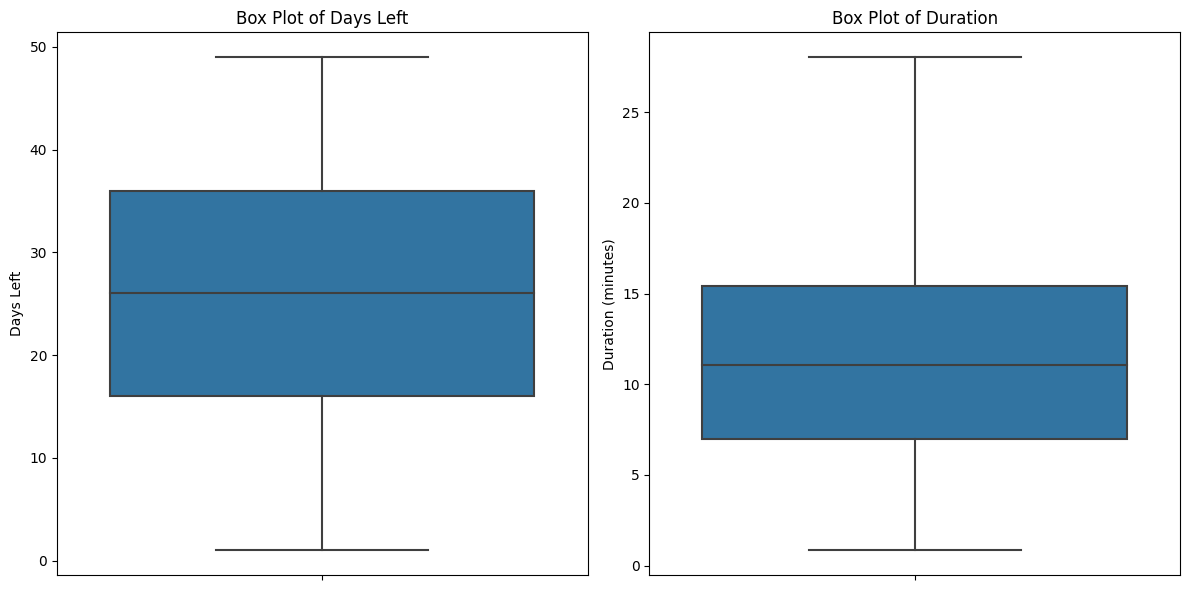

In [24]:
plt.figure(figsize=(12, 6)) # Adjust figure size for better readability

# Boxplot for 'days_left'
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
sns.boxplot(y=X_imputed['days_left'])
plt.title('Box Plot of Days Left')
plt.ylabel('Days Left')

# Boxplot for 'duration'
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
sns.boxplot(y=X_imputed['duration'])
plt.title('Box Plot of Duration')
plt.ylabel('Duration (minutes)')

plt.tight_layout() # Adjusts plot parameters for a tight layout
plt.show()

### `Insight` - This shows that we were able to clear all the outliers in section 2.3. Minimal outliers helps us scale them better.

# 4. Scaling and Encoding features

## 4.1 Scaling the numerical columns/features.

### Numerical features - `duration` `days_left`

Machine learning models (especially KNN, SVR, and gradient boosting) can perform poorly if features are on different scales. We scaled numeric features to bring them to a similar range.

1. MinMaxScaler for 'duration'
   - Scales between 0 and 1
   - Duration is bounded and should be treated on a normalized scale for fair comparison.


2. MaxAbsScaler for 'days_left'
   - Keeps zero-centered values
   - More stable for sparse features or ones with skewed distribution
   - Days left can vary a lot (0 to 60+), so this makes models more robust

In [25]:
from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler

minmax = MinMaxScaler() #duration
maxabs = MaxAbsScaler() #days_left

#fitting on the training data
minmax.fit(X_imputed[['duration']])
maxabs.fit(X_imputed[['days_left']])

#transforming data
X_scaled_minmax = minmax.transform(X_imputed[['duration']])
df_test_scaled_minmax = minmax.transform(df_test_imputed[['duration']])

X_scaled_maxabs = maxabs.transform(X_imputed[['days_left']])
df_test_scaled_maxabs = maxabs.transform(df_test_imputed[['days_left']])


## 4.2 Encoding categorical features

Most ML models can’t handle strings — they need numerical inputs.
So we converted categorical variables using appropriate strategies based on their nature:

| Encoding   | Features                             |
|------------|--------------------------------------|
| Ordinal    | stops, class, departure, arrival     |
| OneHot     | 	airline, source, destination        |


1. Ordinal Encoding
Used when the categories have a natural order or progression.

     Applied to:

    - 'stops': ['zero' < 'one' < 'two_or_more']
    - 'class': ['Economy' < 'Business']
    - 'departure' & 'arrival':
    Time of day has some natural order (Early Morning → Night), so ordinal works better than one-hot.

Why not OneHot? One-hot would treat Morning and Night as completely unrelated, ignoring their sequence.

2. One-Hot Encoding
Used for nominal categories (no order).

     Applied to:
    - 'airline': No meaningful order
    - 'source' and 'destination': Just city names, no ranking

We used OneHotEncoder(handle_unknown='ignore') to avoid breaking the model if new categories show up in test data.



We will drop the flight column as it has high cardinality and it doesnt affect the price until any data about total number of seats is shown

In [26]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

# dropping flight column
X_imputed.drop(columns=['flight'], inplace=True)
df_test_imputed.drop(columns=['flight'], inplace=True)


#for ordinal encoding
stops_order     = ['zero', 'one', 'two_or_more']
class_order     = ['Economy', 'Business']
time_order      = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']

ordinal_features = ['stops', 'class', 'departure', 'arrival']
ordinal_categories = [stops_order, class_order, time_order, time_order]

onehot_features = ['airline', 'source', 'destination']


# Ordinal encoder pipeline
ordinal_pipe = Pipeline(steps=[
    ('ode', OrdinalEncoder(categories=ordinal_categories))
])

# OneHot encoder pipeline
onehot_pipe = Pipeline(steps=[
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# ColumnTransformer
encoding_transformer = ColumnTransformer(transformers=[
    ('ord', ordinal_pipe, ordinal_features),
    ('onehot', onehot_pipe, onehot_features)
], remainder='drop')

# Fit on train data only
encoding_transformer.fit(X_imputed)

# Transform both train and test
X_encoded = encoding_transformer.transform(X_imputed)
df_test_encoded = encoding_transformer.transform(df_test_imputed)

## 4.3 Combining final features

In [27]:
X_final = np.hstack([X_encoded, X_scaled_minmax, X_scaled_maxabs])
df_test_final = np.hstack([df_test_encoded, df_test_scaled_minmax, df_test_scaled_maxabs])

print("Final Train Shape:", X_final.shape)
print("Final Test Shape:", df_test_final.shape)

Final Train Shape: (40000, 24)
Final Test Shape: (10000, 24)


In [28]:
X_final[:1]

array([[1.        , 1.        , 0.        , 4.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 1.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        1.        , 0.        , 1.        , 0.        , 0.        ,
        0.        , 0.        , 0.37656135, 0.81632653]])

In [29]:
df_test_final[:1]

array([[0.        , 0.        , 1.        , 2.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 1.        ,
        1.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 1.        , 0.        ,
        0.        , 0.        , 0.06759735, 0.36734694]])

# 5. Model Building

```
We will build the following models:

- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor
- XGBoost Regressor
- KNN Regressor
```

## 5.0 Splitting the train dataset into training and validation set.

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

X_train, X_val, y_train, y_val = train_test_split(X_final, y, test_size=0.2, random_state=17)

performance = {}

## 5.1 Linear Regression

In [31]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()

lin_reg.fit(X_train,y_train)
y_pred_lin_reg = lin_reg.predict(X_val)

r2_lin_reg = r2_score(y_val,y_pred_lin_reg)
print(r2_lin_reg)
performance['linear_regression'] = r2_lin_reg

0.9085395991034011


## 5.2 Ridge Regression

In [32]:
from sklearn.linear_model import Ridge


ridge = Ridge()


ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_val)

ridge_r2 = r2_score(y_val, y_pred_ridge)

print(ridge_r2)
performance['Ridge regression'] = ridge_r2

0.9085390674438101


#### `Interpretation` - This tells us our model is not overfitting much — that's why Ridge isn’t needing to penalize large weights.

## 5.3 Lasso Regression

In [33]:
from sklearn.linear_model import Lasso


lasso = Lasso()


lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_val)
lasso_r2 = r2_score(y_val, y_pred_lasso)

print(lasso_r2)
performance['Lasso regression'] = lasso_r2

0.9085357650005478


#### `Interpretation` - This consistency means our data is very well-conditioned for linear models. All features contribute relatively evenly — Lasso didn’t need to zero out much.

## 5.4 Decision Tree Regressor

In [34]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(random_state=42)

tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_val)

tree_r2 = r2_score(y_val, y_pred_tree)

print(tree_r2)
performance['Decision Tree'] = tree_r2

0.9477492667804646


#### `Interpretation` - Decision Tree just gave us R² = 0.9477, which is a ~4% improvement over linear models.

## 5.5 Random Forest Regressor

In [35]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_val)

rf_r2 = r2_score(y_val, y_pred_rf)
print(rf_r2)

performance['Random Forest'] = rf_r2


0.9693601325169894


#### `Interpretation` - Ensemble methods like RandomForest smooth out overfitting from Decision Tree. Shows that our data has strong non-linear patterns and feature interactions

## 5.6 Gradient Boosting Regressor

In [36]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(random_state=42)

gbr.fit(X_train, y_train)
y_pred_gbr = gbr.predict(X_val)

gbr_r2 = r2_score(y_val, y_pred_gbr)
print(gbr_r2)

performance['Gradient Boosting'] = gbr_r2


0.9473044215344614


#### `Interpretation` - It’s close to Decision Tree, so no regression here. The default GradientBoostingRegressor is very shallow by default max_depth=3, n_estimators=100.

We will likely improve this a lot with tuning

## 5.7 XGBoost Regressor

In [37]:
from xgboost import XGBRegressor

xgb = XGBRegressor(random_state=42, verbosity=0)

xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_val)

xgb_r2 = r2_score(y_val, y_pred_xgb)
print(xgb_r2)

performance['XGBoost'] = xgb_r2


0.9663305962860226


#### `Interpretation` - Why XGBoost? 
- Regularization is built-in (alpha, lambda)
- Handles missing values smartly

XGBoost performed very close to Random Forest — which means it's learning well even without tuning. With hyperparameter tuning, XGBoost might surpass RF.

## 5.8 KNN Regressor

In [38]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor()  # Default n_neighbors = 5

knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_val)

knn_r2 = r2_score(y_val, y_pred_knn)
print(knn_r2)

performance['KNN Regressor'] = knn_r2


0.9314873079599336


#### `Interpretation` - KNN did better than the linear models — that means there’s local structure in the data!

# 6. Hyperparameter tuning

In this section, we will tune some hyperparameters for the following models:
- Random Forest
- XGBost
- Gradient Boosting
- Decision Tree


Tuning Strategy - `GridSearchCV` or `RandomizedSearchCV`

## 6.1 Random Forest tuning

In [39]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Base model
rf = RandomForestRegressor(random_state=42)

# Param distribution
param_dist = {
    'n_estimators': randint(100, 300),       
    'max_depth': randint(5, 30),              
    'min_samples_split': randint(2, 10),      
    'min_samples_leaf': randint(1, 5),        
    'max_features': ['auto', 'sqrt', 'log2']  
}

# Randomized Search
rf_search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=20,
    scoring='r2',
    cv=3,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

# Fit on full training set
rf_search.fit(X_train, y_train)

# Evaluate
best_rf = rf_search.best_estimator_
rf_tuned_r2 = r2_score(y_val, best_rf.predict(X_val))

print("Best Random Forest R²:", rf_tuned_r2)
performance['Random Forest (Tuned)'] = rf_tuned_r2


Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.11/dist-packages/sklearn/ensemble/_forest.py:413: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features=1.0` or remove this parameter as it is also the default value for RandomForestRegressors and ExtraTreesRegressors.
  warn(
/usr/local/lib/python3.11/dist-packages/sklearn/ensemble/_forest.py:413: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features=1.0` or remove this parameter as it is also the default value for RandomForestRegressors and ExtraTreesRegressors.
  warn(
/usr/local/lib/python3.11/dist-packages/sklearn/ensemble/_forest.py:413: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features=1.0` or remove this parameter as it is also the default value for RandomForestRegressors

Best Random Forest R²: 0.9672318262230897


In [40]:
print("Best Parameters (Random Forest):")
print(rf_search.best_params_)

Best Parameters (Random Forest):
{'max_depth': 25, 'max_features': 'auto', 'min_samples_leaf': 4, 'min_samples_split': 3, 'n_estimators': 121}


## 6.2 XGBoost tuning

In [41]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

xgb = XGBRegressor(random_state=42, verbosity=0)

param_dist = {
    'n_estimators': randint(100, 300),
    'max_depth': randint(3, 15),
    'learning_rate': uniform(0.01, 0.2),
    'subsample': uniform(0.7, 0.3),
    'colsample_bytree': uniform(0.7, 0.3),
    'reg_lambda': uniform(0.0, 1.0),  # L2 regularization
    'reg_alpha': uniform(0.0, 1.0),   # L1 regularization
}

xgb_search = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist,
    n_iter=20,
    scoring='r2',
    cv=3,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_
xgb_tuned_r2 = r2_score(y_val, best_xgb.predict(X_val))

print("Best XGBoost R²:", xgb_tuned_r2)
performance['XGBoost (Tuned)'] = xgb_tuned_r2

# Print best params
print("Best Parameters (XGBoost):")
print(xgb_search.best_params_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best XGBoost R²: 0.9700658944552762
Best Parameters (XGBoost):
{'colsample_bytree': 0.9266084230952957, 'learning_rate': 0.09503117489824894, 'max_depth': 8, 'n_estimators': 205, 'reg_alpha': 0.5677003278199915, 'reg_lambda': 0.03131329245555858, 'subsample': 0.9526854323784995}


## 6.3 GradientBoostingRegressor tuning

In [42]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

gbr = GradientBoostingRegressor(random_state=42)

param_dist = {
    'n_estimators': randint(100, 300),
    'learning_rate': uniform(0.01, 0.2),
    'max_depth': randint(3, 10),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 5),
    'subsample': uniform(0.7, 0.3)
}

gbr_search = RandomizedSearchCV(
    gbr,
    param_distributions=param_dist,
    n_iter=20,
    scoring='r2',
    cv=3,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

gbr_search.fit(X_train, y_train)

best_gbr = gbr_search.best_estimator_
gbr_tuned_r2 = r2_score(y_val, best_gbr.predict(X_val))

print("Best Gradient Boosting R²:", gbr_tuned_r2)
performance['Gradient Boosting (Tuned)'] = gbr_tuned_r2

# Best params
print("Best Parameters (Gradient Boosting):")
print(gbr_search.best_params_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Gradient Boosting R²: 0.9706430007731478
Best Parameters (Gradient Boosting):
{'learning_rate': 0.08897630363511394, 'max_depth': 9, 'min_samples_leaf': 3, 'min_samples_split': 4, 'n_estimators': 180, 'subsample': 0.9134025858245949}


## 6.3 Decision Tree tuning

In [43]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

dt = DecisionTreeRegressor(random_state=42)

param_dist = {
    'max_depth': randint(3, 30),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['auto', 'sqrt', 'log2', None]
}

dt_search = RandomizedSearchCV(
    dt,
    param_distributions=param_dist,
    n_iter=20,
    scoring='r2',
    cv=3,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

dt_search.fit(X_train, y_train)

best_dt = dt_search.best_estimator_
dt_tuned_r2 = r2_score(y_val, best_dt.predict(X_val))

print("Best Decision Tree R²:", dt_tuned_r2)
performance['Decision Tree (Tuned)'] = dt_tuned_r2

# Print best hyperparameters
print("Best Parameters (Decision Tree):")
print(dt_search.best_params_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.11/dist-packages/sklearn/tree/_classes.py:277: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features=1.0'`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/tree/_classes.py:277: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features=1.0'`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/tree/_classes.py:277: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features=1.0'`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/tree/_classes.py:277: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features=1.0'`.
  warnings.warn(
/usr/local/lib/python3.11/di

Best Decision Tree R²: 0.9602395885523186
Best Parameters (Decision Tree):
{'max_depth': 25, 'max_features': None, 'min_samples_leaf': 9, 'min_samples_split': 4}


# 7. Comparison of model performances

In [44]:
df_perf = pd.DataFrame(performance.items(), columns=['Model', 'R² Score'])
df_perf.sort_values(by='R² Score', ascending=False, inplace=True)
print("Model Performance Table")
display(df_perf)

Model Performance Table


,Model,R² Score
10,Gradient Boosting (Tuned),0.970643
9,XGBoost (Tuned),0.970066
4,Random Forest,0.969360
8,Random Forest (Tuned),0.967232
6,XGBoost,0.966331
11,Decision Tree (Tuned),0.960240
3,Decision Tree,0.947749
5,Gradient Boosting,0.947304
7,KNN Regressor,0.931487
0,linear_regression,0.908540


| Model                     | R² Score   |
|---------------------------|------------|
| Gradient Boosting (Tuned) | 0.97064    |
| XGBoost (Tuned)           | 0.97007    |
| Random Forest (Tuned)     | 0.96723    |
| Random Forest             | 0.96936    |
| Decision Tree             | 0.94775    |
| Gradient Boosting         | 0.94730    |
| Decision Tree (Tuned)     | 0.96024    |
| XGBoost                   | 0.96633    |
| KNN Regressor             | 0.93149    |
| Ridge regression          | 0.90854    |
| linear_regression         | 0.90854    |
| Lasso regression          | 0.90854    |
| SVR                       | -0.32263   |


This table displays the R² score of all regression models tested on the validation set. As observed, the **Gradient Boosting Regressor (Tuned)** outperforms all other models with an R² score of 0.97064, closely followed by **XGBoost Regressor (Tuned)** and **Random Forest (Tuned)**.

Simple linear models like Linear Regression, Ridge, and Lasso performed reasonably well.

# 8. Final Submission

In [45]:
# Predicting on final test data
y_test_pred = best_gbr.predict(df_test_final)

final_df_test = pd.read_csv('/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/test.csv')

submission = pd.DataFrame({
    'id': final_df_test['id'],  # use the original test dataframe's 'id' column
    'price': y_test_pred
})


submission.to_csv('submission.csv', index=False)